# Drift detection with Page-Hinkley and Kolmogorov-Smirnov

The detector runs on each telemetry feature separately and does not use labels.
Page-Hinkley (PHT) raises candidate alarms; a candidate is confirmed when a
Kolmogorov-Smirnov (KS) test finds that the two preceding windows of 500 samples differ.
Confirmed alarms closer than 800 samples are merged into one.

Produces Fig. 4 and the detection statistics: phase boundaries found, false alarms and
detection delay, per feature and for all features together.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from utils import (FEATURES, PHASE_NAMES, load_dataset, make_phased_stream, pht_ks_alarms,
                   merge_close_alarms)

DATA_DIR = "data"
FIG_DIR = "figures"
SEED = 42
TOLERANCE = 2000   # an alarm within this many samples after a boundary counts as a detection

os.makedirs(FIG_DIR, exist_ok=True)

_, test_df = load_dataset(DATA_DIR)
X_stream, y_stream, phase_starts = make_phased_stream(test_df, seed=SEED)
boundaries = phase_starts[1:]

In [2]:
def score(alarms, boundaries, tolerance=TOLERANCE):
    """Boundaries detected, false alarms and mean detection delay."""
    delays = []
    for b in boundaries:
        hits = [a for a in alarms if b <= a <= b + tolerance]
        if hits:
            delays.append(hits[0] - b)
    false_alarms = sum(not any(b <= a <= b + tolerance for b in boundaries) for a in alarms)
    return {"boundaries found": f"{len(delays)}/{len(boundaries)}",
            "false alarms": false_alarms,
            "mean delay": np.mean(delays) if delays else np.nan}

## Detection per feature and for all features together

In [3]:
rows, all_confirmed, alarms = [], [], {}
for feature in FEATURES:
    candidates, confirmed = pht_ks_alarms(X_stream[feature].to_numpy())
    merged = merge_close_alarms(confirmed)
    alarms[feature] = (candidates, merged)
    all_confirmed += confirmed
    rows.append({"feature": feature, "PHT candidates": len(candidates),
                 "confirmed alarms": len(merged), **score(merged, boundaries)})

union = merge_close_alarms(all_confirmed)
rows.append({"feature": "any feature", "PHT candidates": np.nan,
             "confirmed alarms": len(union), **score(union, boundaries)})
print("merged alarms on any feature:", union)
pd.DataFrame(rows).set_index("feature").round(0)

merged alarms on any feature: [3650, 5475, 8053, 10310, 11840, 15348, 20170, 24421]


,PHT candidates,confirmed alarms,boundaries found,false alarms,mean delay
feature,,,,,
Laser current (mA),156.0,6,4/4,1,355.0
LP power (dBm),48.0,2,2/4,0,403.0
OSNR (dB),113.0,4,2/4,2,544.0
BER (dB),250.0,3,2/4,1,449.0
any feature,NaN,8,4/4,3,326.0


## Effect of the KS significance level

A looser KS test confirms more PHT candidates, so there are more false alarms. A false
alarm just before a boundary also absorbs the real alarms that follow it when close alarms
are merged, which delays the detection or hides it. All features together.

In [4]:
rows = []
for ks_alpha in [0.005, 0.01, 0.05, 0.1, 0.2]:
    confirmed = []
    for feature in FEATURES:
        confirmed += pht_ks_alarms(X_stream[feature].to_numpy(), ks_alpha=ks_alpha)[1]
    rows.append({"KS alpha": ks_alpha, **score(merge_close_alarms(confirmed), boundaries)})
pd.DataFrame(rows).set_index("KS alpha").round(0)

,boundaries found,false alarms,mean delay
KS alpha,,,
0.005,4/4,3,326.0
0.010,4/4,4,326.0
0.050,3/4,10,344.0
0.100,4/4,13,436.0
0.200,4/4,17,523.0


## Fig. 4: drift alarms on each feature

The detector works on BER as stored in the dataset (10·log10(BER)); only the plotted
values are divided by 10.

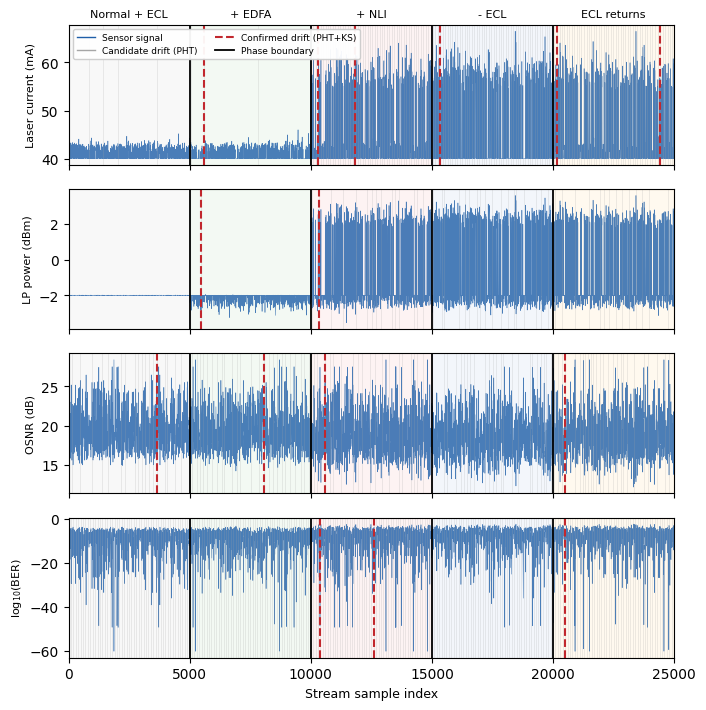

In [5]:
band_colors = ["#f2f2f2", "#e8f4e8", "#fde9e9", "#e9eef9", "#fff4e0"]
edges = phase_starts + [len(y_stream)]

fig, axes = plt.subplots(4, 1, figsize=(7.16, 7.2), sharex=True)
for ax, feature in zip(axes, FEATURES):
    values = X_stream[feature].to_numpy()
    if feature == "BER (dB)":
        values = values / 10
    every_5th = np.arange(0, len(values), 5)
    ax.plot(every_5th, values[every_5th], lw=0.4, color="#1f5fa8", alpha=0.8)

    candidates, merged = alarms[feature]
    for t in candidates:
        ax.axvline(t, color="0.65", lw=0.4, alpha=0.35)
    for t in merged:
        ax.axvline(t, color="#c1272d", ls="--", lw=1.5)

    for k in range(len(phase_starts)):
        ax.axvspan(edges[k], edges[k + 1], color=band_colors[k], alpha=0.5, zorder=0)
    for b in boundaries:
        ax.axvline(b, color="black", lw=1.3)

    ax.set_ylabel("log$_{10}$(BER)" if feature == "BER (dB)" else feature, fontsize=8)
    ax.ticklabel_format(axis="y", useOffset=False, style="plain")
    ax.margins(x=0)

for k, name in enumerate(PHASE_NAMES):
    axes[0].text((edges[k] + edges[k + 1]) / 2, 1.04, name, ha="center", va="bottom",
                 fontsize=8, transform=axes[0].get_xaxis_transform())
axes[-1].set_xlabel("Stream sample index", fontsize=9)

legend = [Line2D([0], [0], color="#1f5fa8", lw=1, label="Sensor signal"),
          Line2D([0], [0], color="0.65", lw=1, label="Candidate drift (PHT)"),
          Line2D([0], [0], color="#c1272d", ls="--", lw=1.5, label="Confirmed drift (PHT+KS)"),
          Line2D([0], [0], color="black", lw=1.3, label="Phase boundary")]
axes[0].legend(handles=legend, fontsize=6.5, loc="upper left", ncol=2, framealpha=0.95)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_drift_alarms.pdf", bbox_inches="tight")
plt.show()